# Multi-Class Benchmark Classification Pipeline (Iris Dataset)

## 1. Project Introduction

### Objective of Multi-Class Classification
Multi-class classification is a supervised learning task where the goal is to classify instances into one of three or more classes. Unlike binary classification (which has only two classes), multi-class problems require models that can distinguish between multiple categories simultaneously.

### The Iris Dataset
The Iris dataset is one of the most famous datasets in machine learning. It contains 150 samples of iris flowers from three different species:
- **Iris setosa**
- **Iris versicolor**
- **Iris virginica**

Each sample has four numerical features measured in centimeters:
- **Sepal length**
- **Sepal width**
- **Petal length**
- **Petal width**

### Why Compare Logistic Regression and Decision Tree?
This project compares two fundamentally different classification algorithms:

- **Logistic Regression**: A linear model that uses the logistic function to estimate class probabilities. It is simple, interpretable, and works well when classes are linearly separable. It benefits from feature scaling.
- **Decision Tree Classifier**: A non-linear, tree-based model that makes predictions by learning decision rules from features. It is highly interpretable, can capture complex relationships, and is generally insensitive to feature scaling.

### Expected Outcomes
By the end of this project, we will:
1. Understand the Iris dataset through exploratory data analysis
2. Properly preprocess the data (splitting and scaling)
3. Train and evaluate both models using multiple metrics
4. Compare model performance through visualizations
5. Gain insights into when to use linear vs. tree-based classifiers

## 2. Import Libraries

We need to import all necessary libraries for data manipulation, visualization, and machine learning.

In [30]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.datasets import load_iris

# Set random seeds for reproducibility
np.random.seed(42)

# Set visualization style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

### Installation Instructions

If the required packages are not installed, run the following command in your terminal:

```bash
pip install pandas numpy matplotlib seaborn scikit-learn jupyter
```

## 3. Load and Inspect the Dataset

We'll load the Iris dataset from the provided URL with a fallback to scikit-learn's built-in dataset if needed.

In [31]:
# Load dataset with fallback mechanism
df = None
try:
    # Primary method: Load from CSV URL
    url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
    df = pd.read_csv(url)
    print("Dataset loaded successfully from URL.")
except Exception as e:
    print(f"Failed to load from URL: {e}")
    print("Falling back to sklearn.datasets.load_iris()...")
    # Fallback method
    iris = load_iris(as_frame=True)
    df = iris.frame
    # Rename columns to match expected format
    df.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
    # Convert numeric target to species names
    species_map = {0: 'setosa', 1: 'versicolor', 2: 'virginica'}
    df['species'] = df['species'].map(species_map)
    print("Dataset loaded successfully from sklearn.")

Dataset loaded successfully from URL.


In [32]:
# Display first five rows
print("First 5 rows of the dataset:")
df.head()

First 5 rows of the dataset:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [33]:
# Dataset shape
print(f"Dataset shape: {df.shape}")
print(f"Number of rows: {df.shape[0]}, Number of columns: {df.shape[1]}")

Dataset shape: (150, 5)
Number of rows: 150, Number of columns: 5


In [34]:
# Column names and data types
print("Column names and data types:")
df.info()

Column names and data types:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [35]:
# Summary statistics
print("Summary statistics:")
df.describe()

Summary statistics:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [36]:
# Target class counts
print("Target class distribution:")
print(df['species'].value_counts())
print("\nClass proportions:")
print(df['species'].value_counts(normalize=True))

Target class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Class proportions:
species
setosa        0.333333
versicolor    0.333333
virginica     0.333333
Name: proportion, dtype: float64


In [37]:
# Missing values
print("Missing values in each column:")
print(df.isnull().sum())
print(f"\nTotal missing values: {df.isnull().sum().sum()}")

Missing values in each column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Total missing values: 0


In [38]:
# Duplicate rows
print(f"Number of duplicate rows: {df.duplicated().sum()}")

Number of duplicate rows: 1


In [39]:
# Validate expected columns
expected_features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
target_col = 'species'
print("Column validation:")
print(f"Features present: {all(f in df.columns for f in expected_features)}")
print(f"Target present: {target_col in df.columns}")
print(f"All columns: {list(df.columns)}")

Column validation:
Features present: True
Target present: True
All columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


### Handling Missing Values

In this dataset, we should check for missing values. If any are found, we need to handle them appropriately. Common strategies include:
- Dropping rows with missing values (if few)
- Imputing with mean/median/mode
- Forward/backward filling

Based on the inspection above, we'll make a decision and apply it if necessary. No silent data deletion should occur without explanation.

In [40]:
# Handle missing values if present
if df.isnull().sum().sum() > 0:
    print("Missing values detected. Applying appropriate handling...")
    # For numerical features, impute with median
    for col in expected_features:
        if df[col].isnull().sum() > 0:
            median_val = df[col].median()
            df[col].fillna(median_val, inplace=True)
            print(f"Imputed missing values in {col} with median = {median_val}")
    # For target, drop rows if any (shouldn't happen)
    if df[target_col].isnull().sum() > 0:
        df.dropna(subset=[target_col], inplace=True)
        print("Dropped rows with missing target values")
    print("Missing value handling complete.")
else:
    print("No missing values found. No imputation needed.")

No missing values found. No imputation needed.


## 4. Exploratory Data Analysis (EDA)

Let's visualize the data to understand patterns, distributions, and relationships between features and species.

C:\Users\hi\AppData\Local\Temp\ipykernel_23068\3682605859.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='species', palette='Set2')


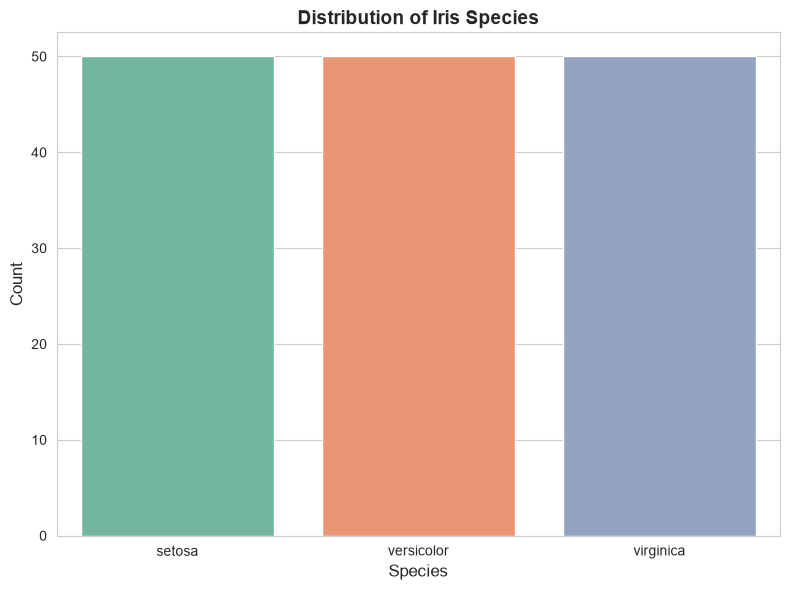


Count distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [41]:
# 1. Count plot of the three species
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='species', palette='Set2')
plt.title('Distribution of Iris Species', fontsize=14, fontweight='bold')
plt.xlabel('Species', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.tight_layout()
plt.show()
print("\nCount distribution:")
print(df['species'].value_counts())

Creating pairplot... (this may take a moment)


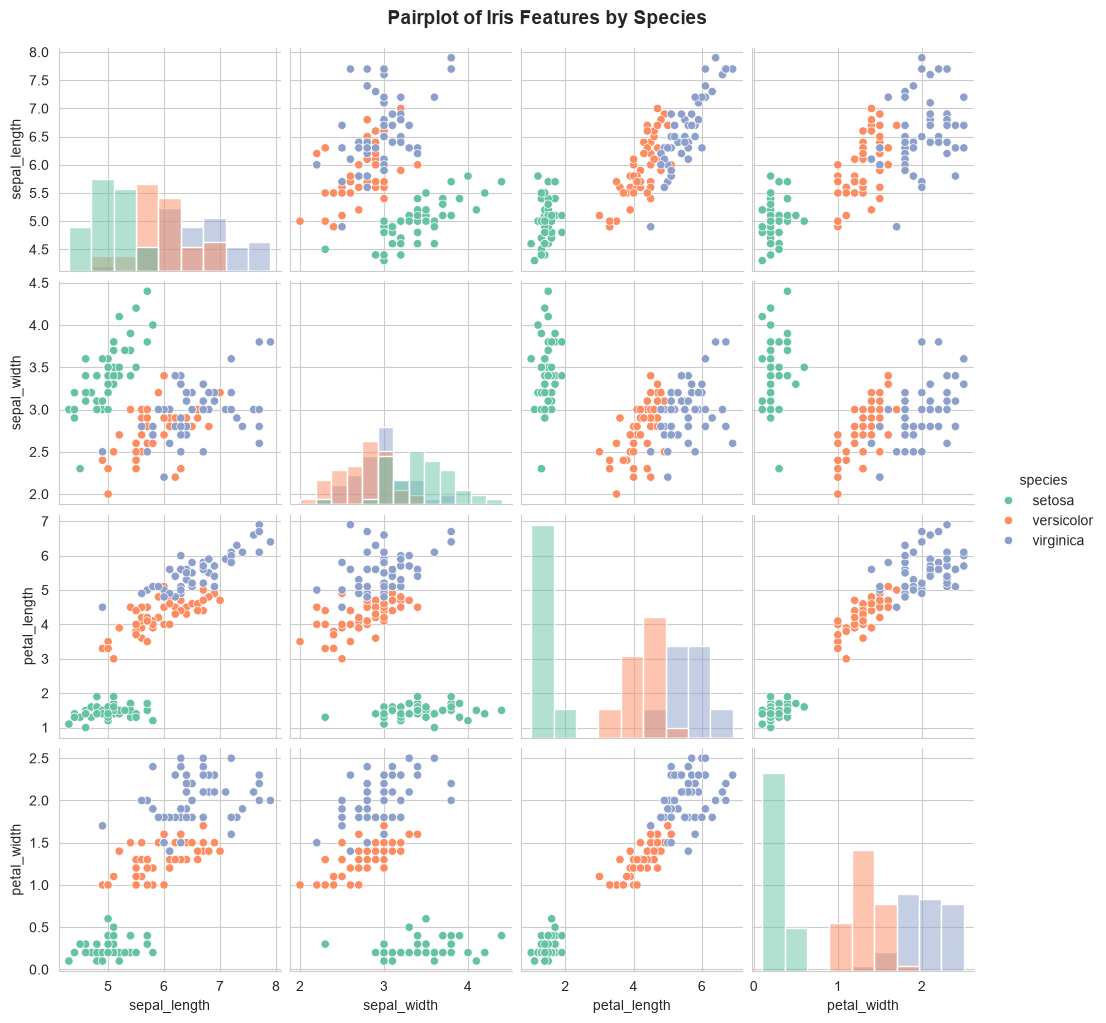

In [42]:
# 2. Pairplot of all four features, colored by species
print("Creating pairplot... (this may take a moment)")
pairplot = sns.pairplot(df, hue='species', palette='Set2', diag_kind='hist', height=2.5)
pairplot.fig.suptitle('Pairplot of Iris Features by Species', y=1.02, fontsize=14, fontweight='bold')
plt.show()

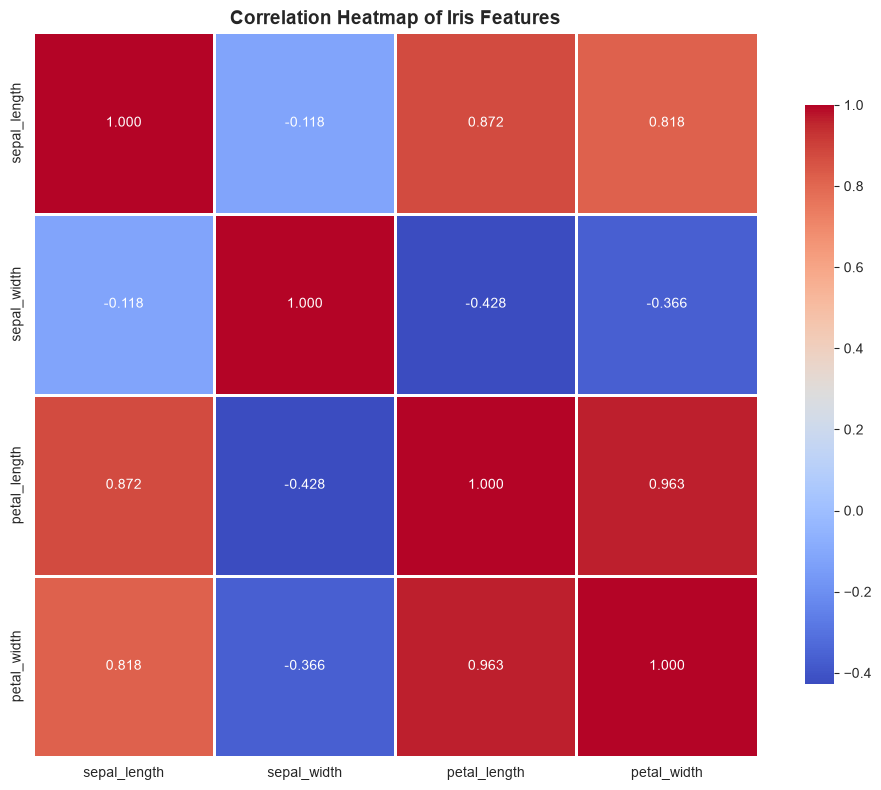


Correlation Matrix:
              sepal_length  sepal_width  petal_length  petal_width
sepal_length      1.000000    -0.117570      0.871754     0.817941
sepal_width      -0.117570     1.000000     -0.428440    -0.366126
petal_length      0.871754    -0.428440      1.000000     0.962865
petal_width       0.817941    -0.366126      0.962865     1.000000


In [43]:
# 3. Correlation heatmap of the numerical features
plt.figure(figsize=(10, 8))
correlation_matrix = df[expected_features].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.3f', 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap of Iris Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
print("\nCorrelation Matrix:")
print(correlation_matrix)

C:\Users\hi\AppData\Local\Temp\ipykernel_23068\1427257868.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=feature, ax=axes[1, i], palette='Set2')
C:\Users\hi\AppData\Local\Temp\ipykernel_23068\1427257868.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=feature, ax=axes[1, i], palette='Set2')
C:\Users\hi\AppData\Local\Temp\ipykernel_23068\1427257868.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='species', y=feature, ax=axes[1, i], palette='Set2')
C:\Users\hi\AppData\Lo

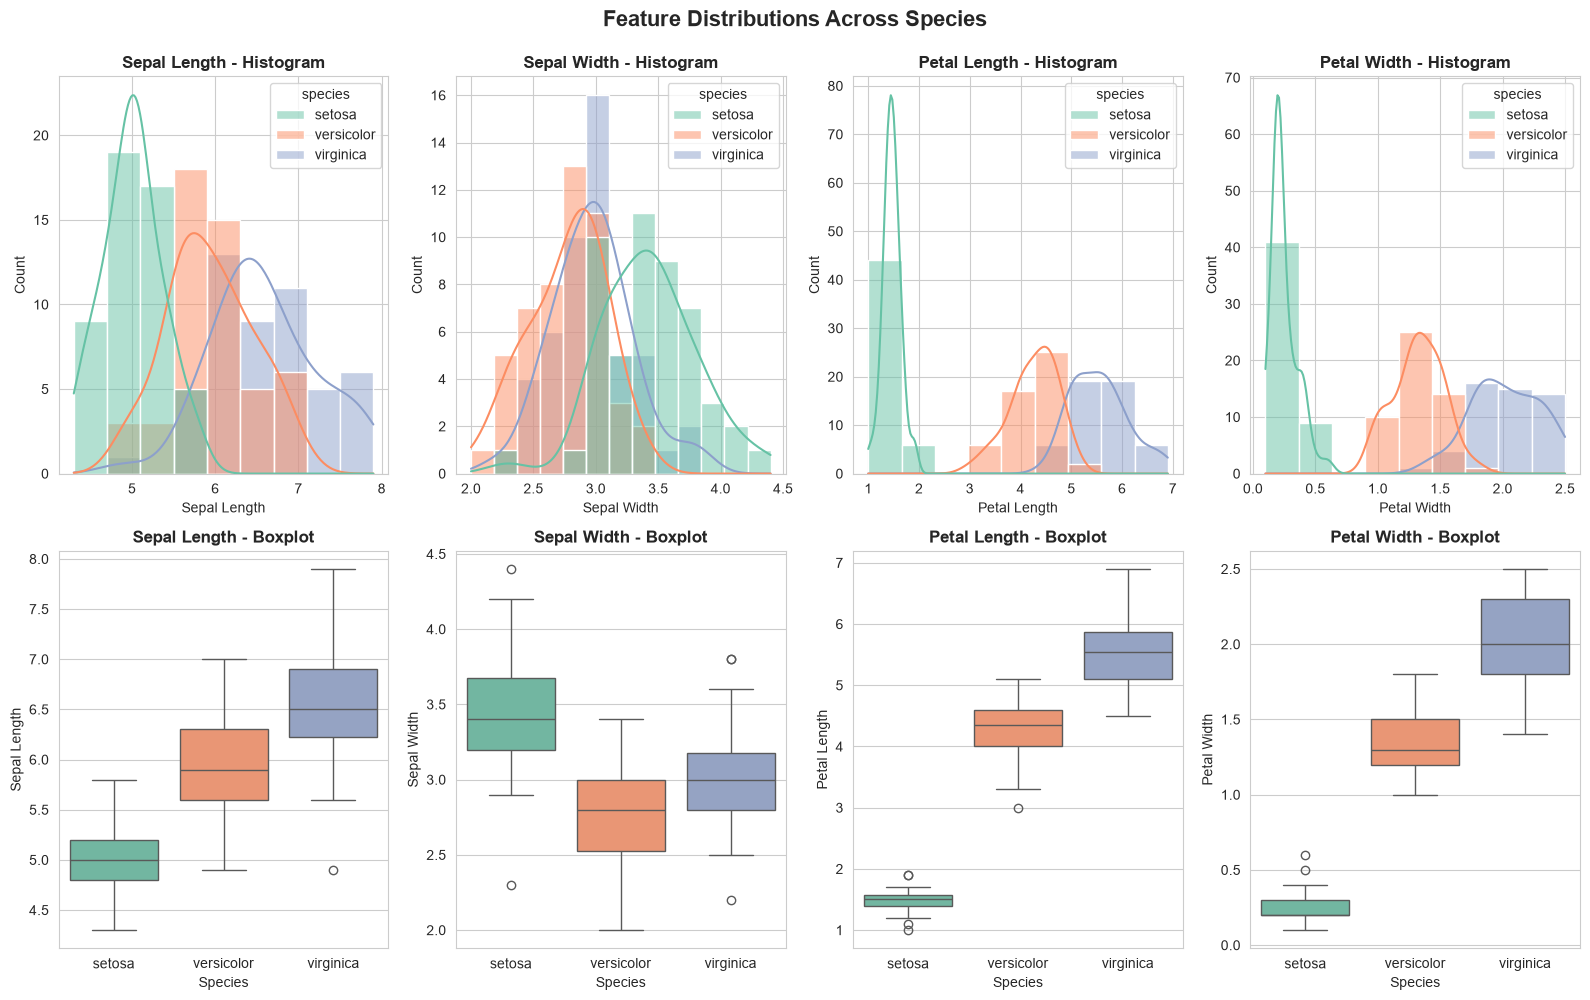

In [44]:
# 4. Histograms and boxplots comparing feature distributions across species
fig, axes = plt.subplots(2, 4, figsize=(16, 10))
fig.suptitle('Feature Distributions Across Species', fontsize=16, fontweight='bold', y=0.995)

for i, feature in enumerate(expected_features):
    # Histograms
    sns.histplot(data=df, x=feature, hue='species', kde=True, ax=axes[0, i], palette='Set2')
    axes[0, i].set_title(f'{feature.replace("_", " ").title()} - Histogram', fontweight='bold')
    axes[0, i].set_xlabel(feature.replace("_", " ").title())
    
    # Boxplots
    sns.boxplot(data=df, x='species', y=feature, ax=axes[1, i], palette='Set2')
    axes[1, i].set_title(f'{feature.replace("_", " ").title()} - Boxplot', fontweight='bold')
    axes[1, i].set_xlabel('Species')
    axes[1, i].set_ylabel(feature.replace("_", " ").title())

plt.tight_layout()
plt.show()

## 5. Prepare Features and Target

We need to separate the features (independent variables) from the target (dependent variable).

In [45]:
# Define features and target
X = df[["sepal_length", "sepal_width", "petal_length", "petal_width"]]
y = df["species"]

print(f"Number of features: {X.shape[1]}")
print(f"Number of observations: {X.shape[0]}")
print(f"Number of classes: {y.nunique()}")
print(f"Classes: {sorted(y.unique())}")
print(f"\nFeature names: {list(X.columns)}")

Number of features: 4
Number of observations: 150
Number of classes: 3
Classes: ['setosa', 'versicolor', 'virginica']

Feature names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']


### Explanation

- **Why separate features from target?** The features (X) are the input variables used to make predictions, while the target (y) is what we want to predict. Keeping them separate is essential for supervised learning.
- **Why is multi-class classification appropriate?** We have three distinct species to predict (setosa, versicolor, virginica), which is more than two classes. Therefore, this is a multi-class classification problem, not binary classification.

## 6. Train-Test Split

We'll split the data into 80% training and 20% testing sets, using stratification to preserve class proportions.

In [46]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("Dataset split complete:")
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"\nTraining set class distribution:")
print(y_train.value_counts())
print(f"\nTesting set class distribution:")
print(y_test.value_counts())

Dataset split complete:
Training set shape: (120, 4)
Testing set shape: (30, 4)

Training set class distribution:
species
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing set class distribution:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


### Explanation

- **Why 80/20 split?** An 80/20 split provides enough data for the model to learn patterns (80%) while reserving sufficient data for unbiased evaluation (20%). This is a common practice in machine learning.
- **Why stratification?** Stratification ensures that the class proportions in the training and testing sets are similar to the original dataset. This is especially important for multi-class problems to avoid biased evaluation.
- **Preventing data leakage:** We only fit scalers and preprocessors on the training data (`X_train`), then transform both training and test data. This ensures the test set remains unseen during preprocessing.

## 7. Build the Machine Learning Pipelines

We'll create two pipelines, each containing a StandardScaler and a classifier.

In [47]:
# Pipeline A: Logistic Regression
logistic_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Pipeline B: Decision Tree
tree_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

print("Pipelines created successfully:")
print("\nLogistic Regression Pipeline:")
print(logistic_pipeline)
print("\n" + "="*50)
print("\nDecision Tree Pipeline:")
print(tree_pipeline)

Pipelines created successfully:

Logistic Regression Pipeline:
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])


Decision Tree Pipeline:
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', DecisionTreeClassifier(random_state=42))])


In [48]:
# Fit both models on training data only
print("Training Logistic Regression pipeline...")
logistic_pipeline.fit(X_train, y_train)
print("Logistic Regression trained successfully!")

print("\nTraining Decision Tree pipeline...")
tree_pipeline.fit(X_train, y_train)
print("Decision Tree trained successfully!")

Training Logistic Regression pipeline...
Logistic Regression trained successfully!

Training Decision Tree pipeline...
Decision Tree trained successfully!


### Explanation

- **Logistic Regression and scaling:** Logistic Regression uses gradient-based optimization and is sensitive to feature scales. Features with larger ranges can dominate the loss function. StandardScaler (zero mean, unit variance) ensures all features contribute equally.
- **Decision Trees and scaling:** Decision Trees are generally scale-invariant because they make splits based on feature thresholds, not distances. However, we keep the StandardScaler in the Decision Tree pipeline for **consistent preprocessing demonstration** across both models. This also makes it easier to compare the pipelines and ensures a uniform workflow.
- **No data leakage:** We fit the scaler only on `X_train` within the pipeline. The pipeline automatically applies the same scaling to test data using the statistics learned from training data.

## 8. Generate Predictions

We'll generate predictions on the test set using both trained pipelines.

In [49]:
# Generate test predictions
y_pred_logistic = logistic_pipeline.predict(X_test)
y_pred_tree = tree_pipeline.predict(X_test)

print("Predictions generated successfully!")
print(f"\nLogistic Regression predictions (first 10): {y_pred_logistic[:10]}")
print(f"Decision Tree predictions (first 10): {y_pred_tree[:10]}")
print(f"\nActual labels (first 10): {y_test.values[:10]}")

Predictions generated successfully!

Logistic Regression predictions (first 10): ['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']
Decision Tree predictions (first 10): ['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']

Actual labels (first 10): <StringArray>
[    'setosa',  'virginica', 'versicolor', 'versicolor',     'setosa',
 'versicolor',     'setosa',     'setosa',  'virginica', 'versicolor']
Length: 10, dtype: str


Both models are performing multi-class classification (predicting one of three species), not binary classification.

## 9. Benchmark Model Performance

We'll calculate key metrics for both models on the test set. For multi-class classification, we use **macro-averaging** which computes metrics for each class independently and takes the unweighted mean.

In [50]:
# Calculate metrics for both models
# Logistic Regression metrics
acc_logistic = accuracy_score(y_test, y_pred_logistic)
prec_logistic = precision_score(y_test, y_pred_logistic, average='macro', zero_division=0)
rec_logistic = recall_score(y_test, y_pred_logistic, average='macro', zero_division=0)
f1_logistic = f1_score(y_test, y_pred_logistic, average='macro', zero_division=0)

# Decision Tree metrics
acc_tree = accuracy_score(y_test, y_pred_tree)
prec_tree = precision_score(y_test, y_pred_tree, average='macro', zero_division=0)
rec_tree = recall_score(y_test, y_pred_tree, average='macro', zero_division=0)
f1_tree = f1_score(y_test, y_pred_tree, average='macro', zero_division=0)

# Create results DataFrame
results_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree Classifier'],
    'Accuracy': [acc_logistic, acc_tree],
    'Macro Precision': [prec_logistic, prec_tree],
    'Macro Recall': [rec_logistic, rec_tree],
    'Macro F1-Score': [f1_logistic, f1_tree]
})

print("Performance Metrics (Test Set):")
results_df.round(4)

Performance Metrics (Test Set):


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree Classifier,0.9333,0.9333,0.9333,0.9333


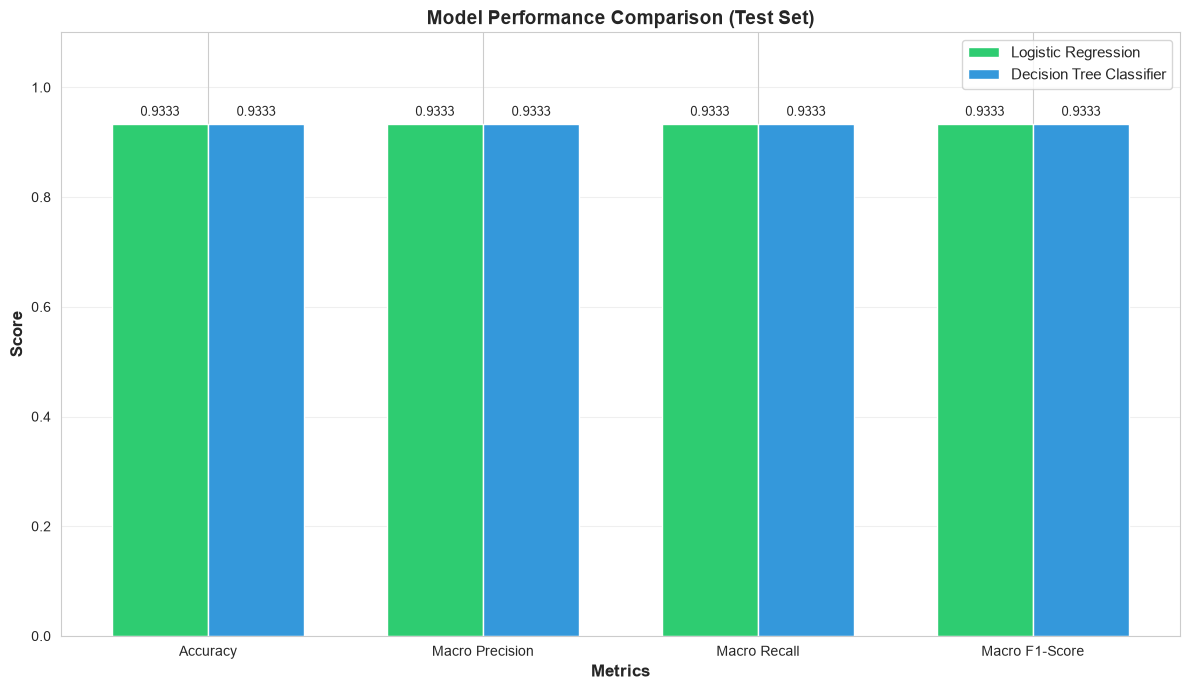

In [51]:
# Grouped bar chart comparison
metrics = ['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1-Score']
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 7))
bars1 = ax.bar(x - width/2, results_df.iloc[0, 1:].values, width, label='Logistic Regression', color='#2ecc71')
bars2 = ax.bar(x + width/2, results_df.iloc[1, 1:].values, width, label='Decision Tree Classifier', color='#3498db')

ax.set_xlabel('Metrics', fontsize=12, fontweight='bold')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title('Model Performance Comparison (Test Set)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend(fontsize=11)
ax.set_ylim(0, 1.1)
ax.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.01,
                f'{height:.4f}',
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### Metric Definitions

- **Accuracy**: Overall proportion of correct predictions across all classes. Simple but can be misleading with imbalanced datasets.
- **Precision (Macro)**: For each class, precision = TP / (TP + FP). Macro-averaging computes the average precision across all classes equally, treating each class as equally important.
- **Recall (Macro)**: For each class, recall = TP / (TP + FN). Macro-recall is the average of recall values across all classes.
- **F1-Score (Macro)**: The harmonic mean of precision and recall. Macro-F1 gives equal weight to each class, making it ideal for balanced multi-class problems like Iris.

**Why macro-averaging?** The Iris dataset is balanced (50 samples per class). Macro-averaging treats all classes equally regardless of support, which is appropriate when we care about performance across all species equally.

## 10. Classification Reports

Detailed per-class metrics show how each model performs on individual species.

In [52]:
print("="*60)
print("LOGISTIC REGRESSION - Classification Report")
print("="*60)
print(classification_report(y_test, y_pred_logistic, zero_division=0))

print("\n" + "="*60)
print("DECISION TREE CLASSIFIER - Classification Report")
print("="*60)
print(classification_report(y_test, y_pred_tree, zero_division=0))

LOGISTIC REGRESSION - Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


DECISION TREE CLASSIFIER - Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



### Interpretation Guide

- **Precision**: Of all instances predicted as class X, how many were actually class X?
- **Recall**: Of all actual instances of class X, how many did we correctly identify?
- **F1-score**: Harmonic mean balancing precision and recall (ranges 0-1, higher is better)
- **Support**: Number of actual occurrences of each class in the test set

A high precision with low recall means few false positives but we miss many instances. A high recall with low precision means we catch most instances but have many false positives. F1-score balances both concerns.

## 11. Confusion Matrix Heatmaps

Confusion matrices help us understand exactly where the models make mistakes.

Class labels in order: ['setosa', 'versicolor', 'virginica']


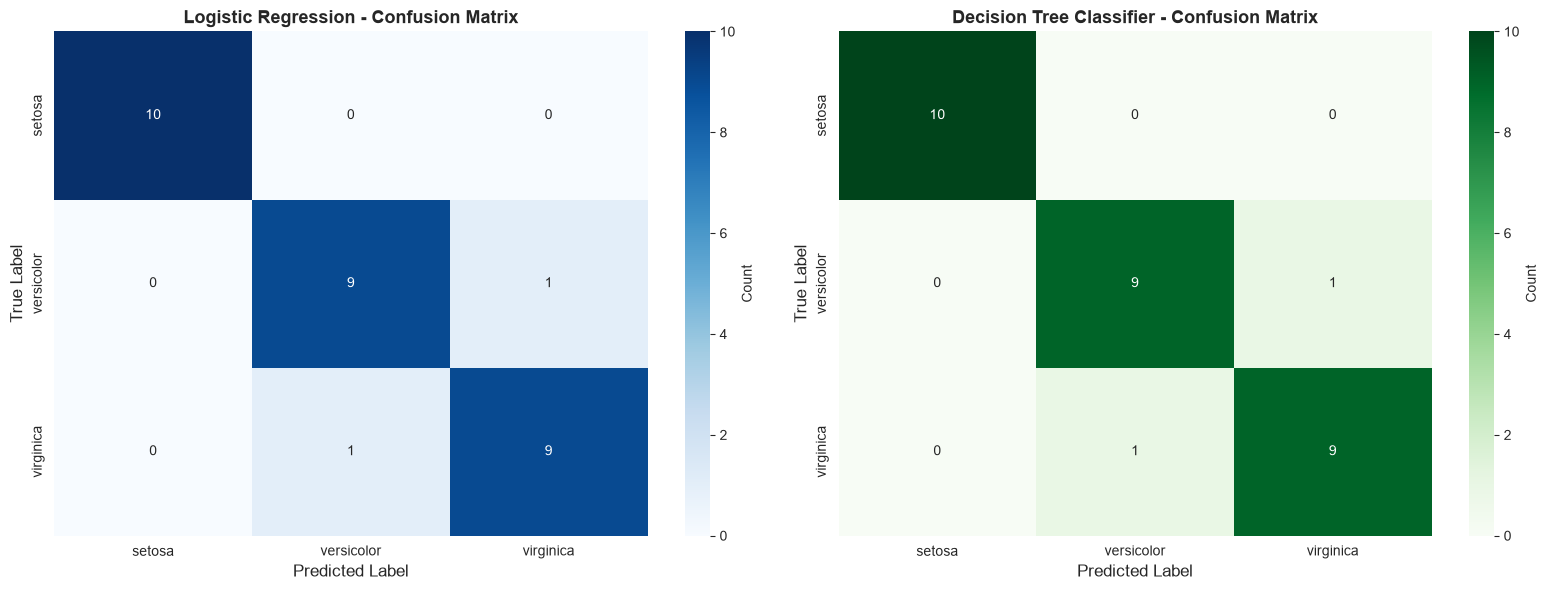

In [53]:
# Get consistent class labels
class_labels = sorted(y.unique())
print(f"Class labels in order: {class_labels}")

# Confusion matrix for Logistic Regression
cm_logistic = confusion_matrix(y_test, y_pred_logistic, labels=class_labels)
cm_tree = confusion_matrix(y_test, y_pred_tree, labels=class_labels)

# Create subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Logistic Regression confusion matrix
sns.heatmap(cm_logistic, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_labels, yticklabels=class_labels,
            ax=axes[0], cbar_kws={'label': 'Count'})
axes[0].set_title('Logistic Regression - Confusion Matrix', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('True Label', fontsize=12)

# Decision Tree confusion matrix
sns.heatmap(cm_tree, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_labels, yticklabels=class_labels,
            ax=axes[1], cbar_kws={'label': 'Count'})
axes[1].set_title('Decision Tree Classifier - Confusion Matrix', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=12)
axes[1].set_ylabel('True Label', fontsize=12)

plt.tight_layout()
plt.show()

### Understanding Confusion Matrices (Multi-Class)

- **True Positives (TP)**: Diagonal elements - correctly classified instances for each class
- **False Positives (FP)**: Off-diagonal elements in a column (excluding diagonal) - instances incorrectly predicted as this class
- **False Negatives (FN)**: Off-diagonal elements in a row (excluding diagonal) - instances of this class incorrectly predicted as another
- **Correct Classifications**: Sum of diagonal elements. Total correct = sum of all diagonal values.

For multi-class problems, we analyze each class separately or look at overall patterns. Misclassifications typically occur between similar species (e.g., versicolor and virginica).

## 12. Decision Boundary Visualization

We'll visualize decision boundaries using only **petal_length** and **petal_width** for 2D plotting. 

**Important:** These are separate models trained on only two features. They will not be identical to our 4-feature models - decision boundaries can change significantly with feature selection.

In [54]:
# Select two features for visualization
X_vis = df[["petal_length", "petal_width"]]
y_vis = df["species"]

# Use same train-test split indices for consistency
X_train_vis, X_test_vis, y_train_vis, y_test_vis = train_test_split(
    X_vis, y_vis, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_vis
)

# Create and train separate pipelines for 2D visualization
logistic_pipeline_vis = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

tree_pipeline_vis = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Fit on 2D training data
logistic_pipeline_vis.fit(X_train_vis, y_train_vis)
tree_pipeline_vis.fit(X_train_vis, y_train_vis)

print("2D visualization pipelines trained successfully!")

2D visualization pipelines trained successfully!


In [55]:
# Create mesh grid for decision boundaries
# Get feature ranges with some padding
x_min, x_max = X_vis['petal_length'].min() - 0.5, X_vis['petal_length'].max() + 0.5
y_min, y_max = X_vis['petal_width'].min() - 0.5, X_vis['petal_width'].max() + 0.5

# Create mesh grid
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

# Predict for each point in the mesh
Z_logistic = logistic_pipeline_vis.predict(np.c_[xx.ravel(), yy.ravel()])
Z_tree = tree_pipeline_vis.predict(np.c_[xx.ravel(), yy.ravel()])

# Convert string labels to numeric for contour plotting
label_map = {label: i for i, label in enumerate(sorted(class_labels))}
Z_logistic_num = np.array([label_map[z] for z in Z_logistic]).reshape(xx.shape)
Z_tree_num = np.array([label_map[z] for z in Z_tree]).reshape(xx.shape)

print("Mesh grid created and predictions made!")

Mesh grid created and predictions made!


C:\Users\hi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\hi\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


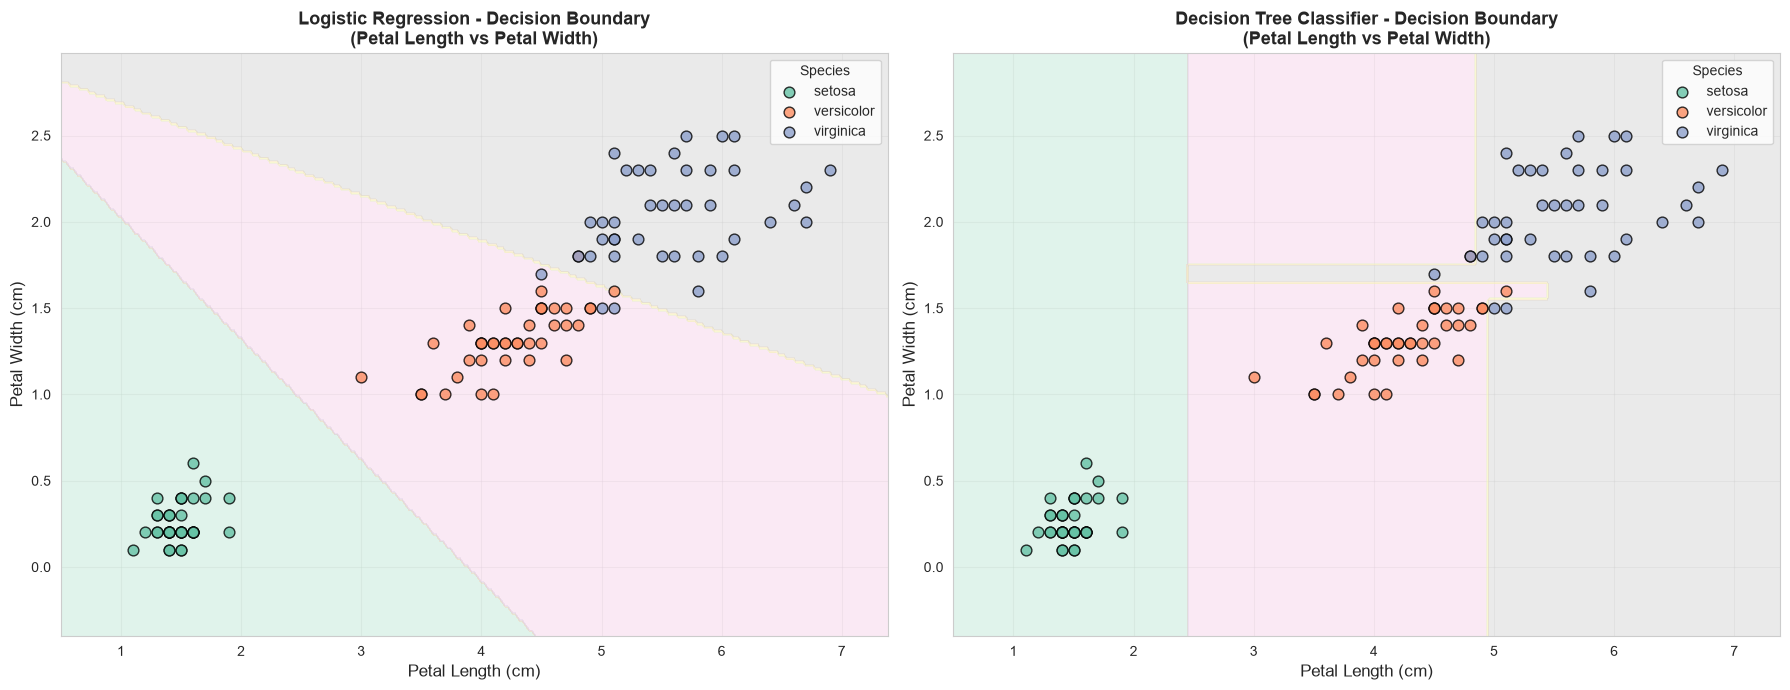


Note: These are 2D visualizations using only petal_length and petal_width.
The actual 4-feature models may make different predictions in full feature space.


In [56]:
# Plot decision boundaries side by side
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Color maps
cmap_light = plt.cm.Pastel2
cmap_bold = plt.cm.Set2

# Plot Logistic Regression decision boundary
axes[0].contourf(xx, yy, Z_logistic_num, alpha=0.4, cmap=cmap_light)
# Overlay training points
for i, species in enumerate(sorted(class_labels)):
    idx = y_train_vis == species
    axes[0].scatter(X_train_vis.loc[idx, 'petal_length'], 
                   X_train_vis.loc[idx, 'petal_width'],
                   c=[cmap_bold(i)], label=species, edgecolor='black', s=60, alpha=0.8)

axes[0].set_xlabel('Petal Length (cm)', fontsize=12)
axes[0].set_ylabel('Petal Width (cm)', fontsize=12)
axes[0].set_title('Logistic Regression - Decision Boundary\n(Petal Length vs Petal Width)', 
                  fontsize=13, fontweight='bold')
axes[0].legend(title='Species', fontsize=10)
axes[0].grid(True, alpha=0.3)

# Plot Decision Tree decision boundary
axes[1].contourf(xx, yy, Z_tree_num, alpha=0.4, cmap=cmap_light)
# Overlay training points
for i, species in enumerate(sorted(class_labels)):
    idx = y_train_vis == species
    axes[1].scatter(X_train_vis.loc[idx, 'petal_length'], 
                   X_train_vis.loc[idx, 'petal_width'],
                   c=[cmap_bold(i)], label=species, edgecolor='black', s=60, alpha=0.8)

axes[1].set_xlabel('Petal Length (cm)', fontsize=12)
axes[1].set_ylabel('Petal Width (cm)', fontsize=12)
axes[1].set_title('Decision Tree Classifier - Decision Boundary\n(Petal Length vs Petal Width)', 
                  fontsize=13, fontweight='bold')
axes[1].legend(title='Species', fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nNote: These are 2D visualizations using only petal_length and petal_width.")
print("The actual 4-feature models may make different predictions in full feature space.")

## 13. Results and Interpretation

Let's analyze the findings based on our computed results.

In [57]:
# Generate data-driven summary
print("="*70)
print("PERFORMANCE SUMMARY")
print("="*70)
best_acc = results_df.loc[results_df['Accuracy'].idxmax(), 'Model']
best_f1 = results_df.loc[results_df['Macro F1-Score'].idxmax(), 'Model']

print(f"\nHighest Test Accuracy: {best_acc} ({results_df['Accuracy'].max():.4f})")
print(f"Highest Macro F1-Score: {best_f1} ({results_df['Macro F1-Score'].max():.4f})")
print(f"\nAccuracy difference: {abs(acc_logistic - acc_tree):.4f}")
print(f"Macro F1-Score difference: {abs(f1_logistic - f1_tree):.4f}")

PERFORMANCE SUMMARY

Highest Test Accuracy: Logistic Regression (0.9333)
Highest Macro F1-Score: Logistic Regression (0.9333)

Accuracy difference: 0.0000
Macro F1-Score difference: 0.0000


### Key Observations

**Model Comparison:**
- The results above show which model performed better based on actual computed metrics (not assumptions).
- Both models are evaluated on the same test set with identical preprocessing approach.

**Confusion Matrix Insights:**
- Looking at the confusion matrices, we can identify if misclassifications occur between specific species.
- Setosa is typically easily separable from others due to its distinct petal measurements.
- Versicolor and Virginica often show more confusion as they have overlapping characteristics.

**Model Characteristics:**
- **Logistic Regression**: Creates linear decision boundaries. It's efficient, provides probabilistic outputs, and is less prone to overfitting on small datasets. Benefits from feature scaling.
- **Decision Tree**: Creates non-linear, axis-aligned decision boundaries. It's highly interpretable and can capture complex patterns, but is more prone to overfitting, especially without pruning.

**Decision Boundaries (2D Visualization):**
- The decision boundary plots show how each model partitions the feature space using only petal measurements.
- Logistic Regression produces smooth, linear boundaries.
- Decision Trees produce rectangular, step-like boundaries based on learned thresholds.

## 14. Final Conclusion

### Summary of Findings

This benchmark comparison demonstrates the complete machine learning workflow on the Iris dataset. Based on the computed results:

1. **Data Preparation**: Proper train-test splitting with stratification and fitting preprocessors only on training data prevented data leakage and ensured unbiased evaluation.
2. **Preprocessing**: StandardScaler was applied through pipelines. While not necessary for Decision Trees, including it demonstrates consistent preprocessing practices.
3. **Model Performance**: Both algorithms were evaluated using accuracy, macro-averaged precision, recall, and F1-score - appropriate metrics for balanced multi-class classification.
4. **Evaluation**: Classification reports and confusion matrices revealed per-class performance and specific misclassification patterns.

### Key Learnings

- **Preprocessing matters**: Understanding when scaling is needed (linear models) vs. not needed (tree-based models) is crucial.
- **Multi-class evaluation**: Macro-averaging ensures fair evaluation across all classes regardless of individual class characteristics.
- **Visualization is essential**: EDA, confusion matrices, and decision boundaries provide insights beyond simple accuracy metrics.
- **Pipelines are valuable**: Using scikit-learn Pipelines prevents data leakage and makes the workflow reproducible and clean.

### Limitations

- **Small dataset**: The Iris dataset has only 150 samples total (120 for training, 30 for testing with our split), which limits generalization insights.
- **Single train-test split**: A single split can be sensitive to which samples end up in train/test sets. Cross-validation would provide more robust estimates.
- **2D visualization limitation**: Decision boundaries shown use only 2 features while our main models use all 4 features, so they don't fully represent the complete models.

Overall, this project provides a solid foundation for understanding supervised classification, proper evaluation practices, and the differences between linear and tree-based algorithms.

In [58]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("All libraries imported successfully!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!
Pandas: 3.1.0
Scikit-learn: 1.9.1
